# INF201 - Deliverable 1

## Task 1: Temperatures 

GitHub repository: https://github.com/ellissandramuller-netizen/INF201-deliverable-1

In [33]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Leser inn klient-ID fra en separat tekstfil og fjerner unødvendige mellomrom
with open('client_id.txt', 'r') as file:
    my_id = file.read().strip()

# Definerer parametere for å hente døgnmiddeltemperaturer fra Ås i 2025
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01",
    "timeoffsets": "default",
    "levels": "default"
}

# Angir URL til Frost API sitt endepunkt for observasjoner
url = "https://frost.met.no/observations/v0.jsonld"

# Sender en GET-forespørsel med parametere og klient-ID for autentisering
response = requests.get(
    url,
    params=parameters,
    auth=(my_id, "")
)

# Konverterer API-responsen til en dictionary
data = response.json()

# Henter ut listen med observasjoner fra responsen
observations = data["data"]

Task 1 – Utforsking og behandling av temperaturdata

Vi undersøkte JSON-responsen fra Frost API med data.keys() og observations[0] for å forstå datastrukturen. Vi oppdaget to tidsforskyvninger (PT0H og PT6H) og valgte PT0H for å bruke én konsekvent tidsserie. Vi kontrollerte også at datasettet dekket alle 365 dagene i 2025.

Deretter organiserte vi temperaturmålingene i en Pandas DataFrame, beregnet gjennomsnitt, median, minimum og maksimum, og visualiserte døgnmiddeltemperaturene i et linjediagram.

In [3]:
# Oppretter en tom liste for å samle datoer og temperaturmålinger
rows = []

# Går gjennom hver dag i observasjonsdataene fra Frost API
for day in observations:
    date = day["referenceTime"]

    # Går gjennom temperaturmålingene for den aktuelle dagen
    for measurement in day["observations"]:

        # Velger kun målinger med tidsforskyvning PT0H
        if measurement["timeOffset"] == "PT0H":
            temperature = measurement["value"]

            # Lagrer dato og temperatur som en dictionary i listen
            rows.append({
                "date": date,
                "temperature": temperature
            })

# Konverterer listen med temperaturdata til en Pandas DataFrame
df = pd.DataFrame(rows)

# Konverterer datoene fra tekst til datetime-format
df["date"] = pd.to_datetime(df["date"])

In [4]:
# Beregner gjennomsnitt, median, minimum og maksimum for døgnmiddeltemperaturene
statistics = df["temperature"].agg(["mean", "median", "min", "max"])

# Konverterer statistikken til en DataFrame med beskrivende kolonnenavn
# og runder av temperaturverdiene til to desimaler
statistics_table = statistics.to_frame(name="Temperature (°C)").round(2)

# Viser tabellen med de beregnede temperaturstatistikkene
print(statistics_table)

        Temperature (°C)
mean                7.87
median              8.30
min               -15.50
max                23.70


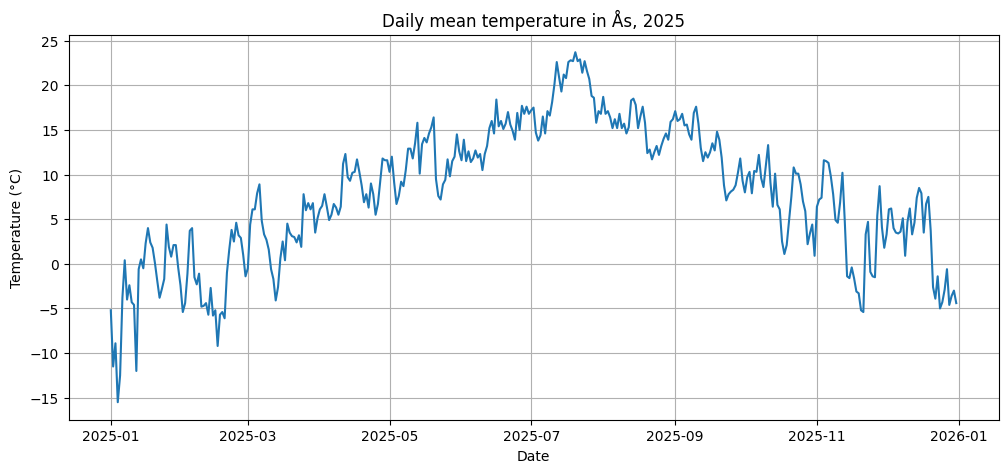

In [5]:
# Oppretter en figur for å visualisere døgnmiddeltemperaturene gjennom året
plt.figure(figsize=(12, 5))

# Plotter døgnmiddeltemperaturene som en sammenhengende linje
plt.plot(df["date"], df["temperature"])

# Legger til aksetitler og en beskrivende figurtittel
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Daily mean temperature in Ås, 2025")

# Legger til rutenett for å gjøre grafen lettere å lese
plt.grid(True)

plt.show()

## Task 2 - Precipitation

In [6]:
# Velger hvilke nedbørsdata vi ønsker å hente fra Frost API
parameters_precipitation = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2026-01-01"
}

# Henter nedbørsdata fra Frost API
url = "https://frost.met.no/observations/v0.jsonld"

response_precipitation = requests.get( # Sender en forespørsel til Frost API
    url,
    params=parameters_precipitation, # Forteller hvilke nedbørsdata vi ønsker
    auth=(my_id, ""),
    timeout=30 # Forespørselen vil time out etter 30 sekunder hvis det ikke kommer noe svar
)

In [7]:
# Gjør om responsen fra Frost API til Python data
data_precipitation = response_precipitation.json()

In [8]:
# Henter ut datoer og nedbørsmengder
dates_precipitation = []
precipitation_values = []

for day in data_precipitation["data"]:
    for observation in day["observations"]:
        # Bruker måleserien PT6H konsekvent gjennom hele året
        if observation["timeOffset"] == "PT6H":
            dates_precipitation.append(day["referenceTime"])
            precipitation_values.append(observation["value"])

In [9]:
# Lager en DataFrame med datoer og nedbørsmengder
df_precipitation = pd.DataFrame({
    "date": dates_precipitation,
    "precipitation": precipitation_values
})

# Gjør om datoene til datetime-format
df_precipitation["date"] = pd.to_datetime(df_precipitation["date"])

# Sorterer datoene i kronologisk rekkefølge
df_precipitation = df_precipitation.sort_values("date").reset_index(drop=True)

In [10]:
# Kontrollerer om det er noen manglende eller dupliserte datoer i nedbørsdataene
expected_dates = pd.date_range(
    "2025-01-01",
    "2025-12-31",
    tz="UTC"
)

missing_dates = expected_dates.difference(df_precipitation["date"])

print("Missing dates:", len(missing_dates))
print("Duplicate dates:", df_precipitation["date"].duplicated().sum())

Missing dates: 0
Duplicate dates: 0


In [11]:
# Kombinerer temperatur- og nedbørsdataene i én DataFrame
df_combined = pd.merge(
    df[["date", "temperature"]],
    df_precipitation,
    on="date",
)

In [12]:
# Kontrollerer at alle 365 dagene ble med
print("combined observations:", len(df_combined))

combined observations: 365


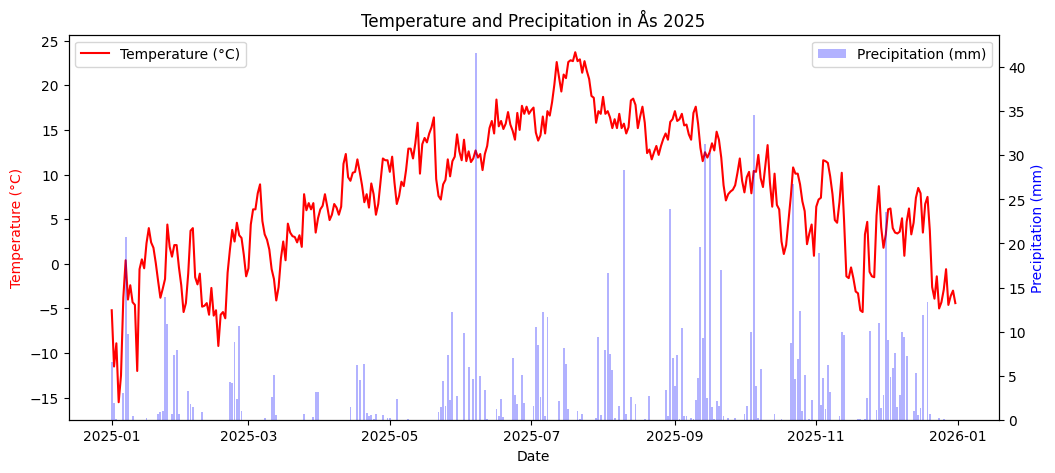

In [13]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(df_combined["date"], 
         df_combined["temperature"], 
         color="red", 
         label="Temperature (°C)"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)", color="red")

# Lager en exstra y-akse for nedbør
ax2 = ax1.twinx()

#viser nedbør som søyler
ax2.bar(df_combined["date"], 
        df_combined["precipitation"], 
        color="blue", 
        alpha=0.3,
        label="Precipitation (mm)"
)

ax2.set_ylabel("Precipitation (mm)", color="blue")

# Legger til tittel og forklaring
plt.title("Temperature and Precipitation in Ås 2025")

ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.show()

Grafen viser døgnmiddeltemperatur og daglig nedbør i Ås gjennom 2025. Temperaturen vises som en rød linje, mens nedbøren vises som blå søyler. brukte to y-akser fordi temperatur og nedbør måle i forskjellige enheter. 

# Task 3 - Historical temperature data

Comparison of daily mean air temperatures in Ås for 1925 and 2025. 

In [14]:
from pathlib import Path
import requests
import matplotlib.pyplot as plt
import pandas as pd

client_id = Path("client_id.txt").read_text().strip()

In [15]:
endpoint = "https://frost.met.no/observations/v0.jsonld"

# Velger målestasjon, daglig gjennomsittstemp og tidsperiode for 1925
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1926-01-01"
}

# Sender en forespørsel til Frost API for å hente temp målingene
response = requests.get(
    endpoint, 
    params=parameters, 
    auth=(client_id, ""),
    timeout=30
)

In [16]:
# Gjør svaret fra Frost API om til Python data
data = response.json()

In [17]:
print(len(data["data"]))

365


In [18]:
# Lager tomme lister for datoer og temperaturer fra 1925
dates_1925 = []
temperatures_1925 = []

# Går gjennom målingene og velger riktig temperatur for hver dag
for day in data["data"]:
    date = day["referenceTime"]

    for observation in day["observations"]:
        if observation.get("timeOffset") == "PT0H":
            dates_1925.append(date)
            temperatures_1925.append(observation["value"])

# Kontrollerer antall datoer og temperaturmålinger
print(len(dates_1925), len(temperatures_1925))

365 365


In [19]:
# Lager en DataFrame med datoer og temperaturerfor 1925
df_1925 = pd.DataFrame({
    "date": dates_1925,
    "temperature": temperatures_1925
}) 

# Gjør om dato-kolonnen til datetime-format
df_1925["date"] = pd.to_datetime(df_1925["date"])

In [20]:
# Velger samme målestasjon og temperaturåling, men for året 2025
parameters_2025 = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01"
}   

# Henter temperaturdata for 2025 fra Frost API
response_2025 = requests.get(
    endpoint, 
    params=parameters_2025, 
    auth=(client_id, ""),
    timeout=30
)

In [21]:
data_2025 = response_2025.json()

print(len(data_2025["data"]))

365


In [22]:
# Lager tomme lister for datoer og temperaturer fra 2025
dates_2025 = []
temperatures_2025 = []

# Går gjennom målingene og velger riktig temperatur for hver dag
for day in data_2025["data"]:
    date = day["referenceTime"]

    for observation in day["observations"]:
        if observation.get("timeOffset") == "PT0H":
            dates_2025.append(date)
            temperatures_2025.append(observation["value"])

# Kontrollerer antall datoer og temperaturmålinger
print(len(dates_2025), len(temperatures_2025))

365 365


In [23]:
# Lager en DataFrame med datoer og temperaturer for 2025
df_2025 = pd.DataFrame({
    "date": dates_2025,
    "temperature": temperatures_2025
})

# Gjør om dato-kolonnen til datetime-format
df_2025["date"] = pd.to_datetime(df_2025["date"])


In [24]:
# Kontrollerer om det mangler noen datoer i 1925-dataene
all_dates_1925 = pd.date_range("1925-01-01", "1925-12-31", tz="UTC")

missing_1925 = all_dates_1925.difference(df_1925["date"])

print(missing_1925)

DatetimeIndex([], dtype='datetime64[ns, UTC]', freq='D')


In [25]:
# Kontrollerer om det mangler noen datoer i 2025-dataene
all_dates_2025 = pd.date_range("2025-01-01", "2025-12-31", tz="UTC")

missing_2025 = all_dates_2025.difference(df_2025["date"])

print(missing_2025)

DatetimeIndex([], dtype='datetime64[ns, UTC]', freq='D')


In [26]:
# Sammenligner temperaturstatistikk for 1925 og 2025
statistics= pd.DataFrame({
    "1925": [
        df_1925["temperature"].mean(),
        df_1925["temperature"].median(),
        df_1925["temperature"].min(),
        df_1925["temperature"].max()
    ],
    "2025": [
        df_2025["temperature"].mean(),
        df_2025["temperature"].median(),
        df_2025["temperature"].min(),
        df_2025["temperature"].max()
    ]
}, index=["mean", "median", "min", "max"])

# Skriver ut statistikken avrundt til to desimaler
print(statistics.round(2))

         1925   2025
mean     5.28   7.87
median   5.30   8.30
min    -20.70 -15.50
max     24.30  23.70


In [27]:
# Finner hvilken dag i året hver temperaturmåling tilhører
df_1925["day_of_year"] = df_1925["date"].dt.dayofyear
df_2025["day_of_year"] = df_2025["date"].dt.dayofyear


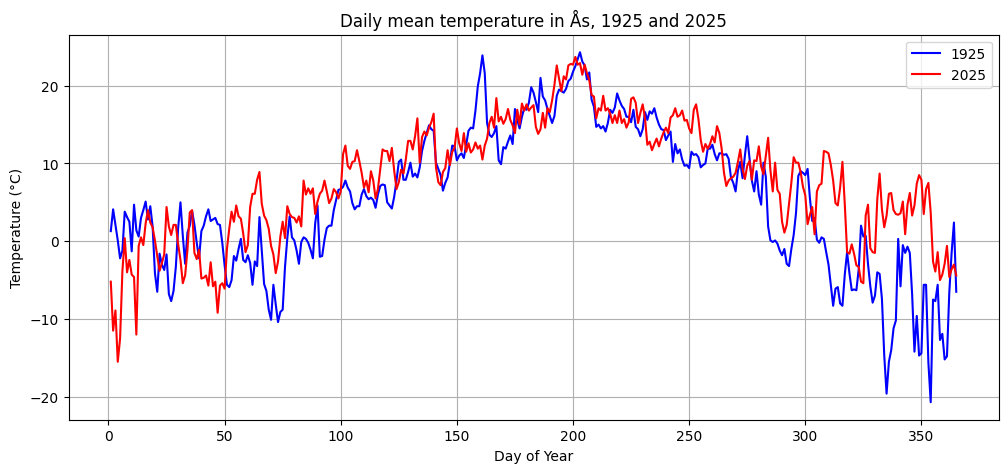

In [28]:
# Lager en graf som sammenligner temperaturene for 1925 og 2025
plt.figure(figsize=(12, 5))

# tegner temperaturene for begge årene i samme graf 
plt.plot(df_1925["day_of_year"], df_1925["temperature"], label="1925", color="blue")
plt.plot(df_2025["day_of_year"], df_2025["temperature"], label="2025", color="red")

plt.xlabel("Day of Year")
plt.ylabel("Temperature (°C)")
plt.title("Daily mean temperature in Ås, 1925 and 2025")

plt.legend()
plt.grid(True)
plt.show()

Den gjennomsnittlige daglige temperaturen var 5,28°C i 1925 og 7,87°C i 2025, en forskjell på 2,59 °C. Den laveste døgnmiddeltemperaturen var også høyere i 2025, mens den høyeste døgnmiddeltemperaturen var litt høyere i 1925.

Grafen viser hvordan temperaturen varierte gjennom de to årene. Selv om gjennomsnittstemperaturen var høyere i 2025, betyr ikke dette at alle dagene i 2025 var varmere enn i 1925.

## Task 4 - Heatwaves in Ås 2025

In [29]:

import yaml

# Henter daglige maksimumstemperaturer fra Frost API
def get_max_temperatures(station_id, year):

    parameters_max = {
        "sources": station_id,
        "elements": "max(air_temperature P1D)",
        "referencetime": f"{year}-01-01/{year + 1}-01-01"
    }

    response_max = requests.get(
        endpoint,
        params=parameters_max,
        auth=(client_id, ""),
        timeout=30
    )

    response_max.raise_for_status()
    data_max = response_max.json()

    # Henter ut datoer og maksimumstemperaturer
    dates_max = []
    temperatures_max = []

    for day in data_max["data"]:
        date = day["referenceTime"]
        temperature = day["observations"][0]["value"]

        dates_max.append(date)
        temperatures_max.append(temperature)

    # Lager en DataFrame med maksimumstemperaturene
    df_max = pd.DataFrame({
        "date": dates_max,
        "temperature": temperatures_max
    })

    # Gjør om datoene til datetime-format og sorterer
    df_max["date"] = pd.to_datetime(df_max["date"], utc=True)
    df_max = df_max.sort_values("date").reset_index(drop=True)

    return df_max
   
  

In [30]:
# Funksjon som teller hetebølger for en valgt målestasjon og et valgt år
def count_heatwaves(station_id, year):

    # Henter maksimumstemperaturene
    df_max = get_max_temperatures(station_id, year)

    # Sjekker om maksimumstemperaturen er minst 27 grader
    df_max["hot_day"] = df_max["temperature"] >= 27

    # Oppretter variabler for å telle varmedager og lagre hetebølger
    consecutive_days = 0
    start_date = None
    previous_date = None
    heatwaves = []

    # Går gjennom dagene og teller sammenhengende varme dager
    for index, row in df_max.iterrows():

        current_date = row["date"]

        # Kontrollerer at datoene følger etter hverandre
        is_next_day = (
            previous_date is not None
            and (current_date - previous_date).days == 1
        )

        if row["hot_day"]:

            # Starter en ny periode dersom datoene ikke er sammenhengende
            if consecutive_days == 0 or not is_next_day:

                # Lagrer en eventuell tidligere hetebølge
                if consecutive_days >= 5:
                    heatwaves.append((
                        start_date,
                        previous_date,
                        consecutive_days
                    ))

                consecutive_days = 1
                start_date = current_date

            else:
                consecutive_days += 1

        else:
            # Registrerer hetebølgen dersom den varte minst 5 dager
            if consecutive_days >= 5:
                heatwaves.append((
                    start_date,
                    previous_date,
                    consecutive_days
                ))

            consecutive_days = 0

        previous_date = current_date

    # Sjekker om en hetebølge fortsetter helt til siste dag
    if consecutive_days >= 5:
        heatwaves.append((
            start_date,
            previous_date,
            consecutive_days
        ))

    # Lager en liste med datoene for hetebølgene
    heatwave_dates = []

    for start, end, days in heatwaves:
        heatwave_dates.append(
            f"{start.date()} - {end.date()}"
        )

    # Henter navnet på målestasjonen fra Frost API
    station_response = requests.get(
        "https://frost.met.no/sources/v0.jsonld",
        params={"ids": station_id},
        auth=(client_id, ""),
        timeout=30
    )

    station_response.raise_for_status()
    station_data = station_response.json()

    station_name = station_data["data"][0]["name"]

    # Lager sammendrag i samme format som eksempelfilen
    summary = {
        "dates": heatwave_dates,
        "station_id": station_id,
        "station_name": station_name,
        "year": year
    }

    # Lagrer sammendraget som YAML-fil
    output_file = f"heatwaves_{station_id}_{year}.yml"

    with open(output_file, "w", encoding="utf-8") as file:
        yaml.safe_dump(
            summary,
            file,
            sort_keys=False,
            allow_unicode=True
        )

    return heatwaves
    return heatwaves

In [31]:
heatwaves = count_heatwaves("SN17850", 2025)

# Skriver ut antall hetebølger
print("Number of heatwaves:", len(heatwaves))

# Skriver ut startdato, sluttdato og varighet
for start, end, days in heatwaves:
    print(f"Heatwave: {start.date()} to {end.date()} ({days} days)")

Number of heatwaves: 1
Heatwave: 2025-07-16 to 2025-07-20 (5 days)


Vi fant én hetebølge i Ås i 2025, fra 16. til 20. juli. Perioden varte i fem sammenhengende dager med en maksimumstemperatur på minst 27°C. Resultatet ble lagret i en YAML-fil med informasjon om målestasjon, år og datoene for hetebølgen.

## Task 5

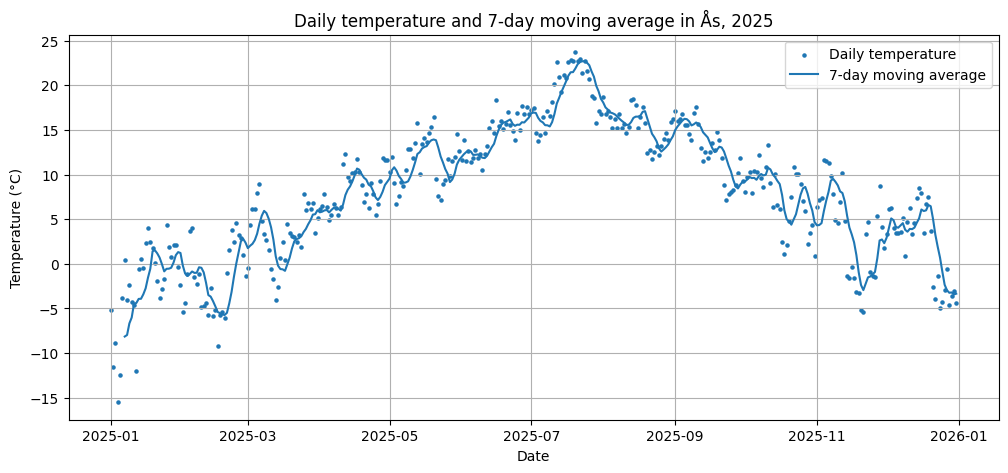

In [32]:
# Funksjon som beregner 7-dagers glidende gjennomsnitt
def moving_average(temperatures: pd.Series) -> pd.Series:
    """Calculate the 7-day moving average of daily temperatures."""

    average = temperatures.rolling(window=7).mean()

    return average


# Bruker funksjonen på døgnmiddeltemperaturene fra Task 1
# og lagrer resultatet i en ny kolonne i DataFramen
df["moving_average"] = moving_average(df["temperature"])


# Oppretter en figur for å sammenligne daglige temperaturer og glidende gjennomsnitt
plt.figure(figsize=(12, 5))

# Viser de daglige temperaturene som punkter
plt.scatter(df["date"], df["temperature"], s=5, label="Daily temperature")

# Viser 7-dagers glidende gjennomsnitt som en sammenhengende linje
plt.plot(df["date"], df["moving_average"], label="7-day moving average")

# Legger til aksetitler, figurtittel, tegnforklaring og rutenett
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Daily temperature and 7-day moving average in Ås, 2025")
plt.legend()
plt.grid(True)
plt.show()


Task 5 – Glidende gjennomsnitt

Vi opprettet funksjonen moving_average() som beregner et 7-dagers glidende gjennomsnitt ved hjelp av rolling(window=7).mean(). De første seks dagene får verdien NaN, siden beregningen krever syv målinger.

Vi visualiserte de daglige temperaturene som punkter og det glidende gjennomsnittet som en linje for å tydeliggjøre temperaturutviklingen gjennom året.